# E. coli: local recombination and mutation rates, and hotspots

This notebook repeats the *E. coli* analysis of the paper (Section 3.4):

1. load the observed summary statistics of 836 alignment blocks of 27 *E. coli* genomes;
2. train NPE on 50,000 ClonalOrigin simulations on the *E. coli* clonal genealogy;
3. sample the posterior of $(\rho_s, \theta_s, \ell)$ for every block;
4. detect recombination and mutation hotspots with the ppDoG detector.

Run it from the `examples` folder. 
The trained posterior is saved in `data/`, and later runs load it instead of training again.

In [1]:
from pathlib import Path
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch

from bacnpe.summary_stats import STAT_NAMES
from bacnpe.npe import LeaveLengthOut_NN, train_npe, save_npe, load_npe, sample_posteriors
from bacnpe.detection import detect_hotspots, save_hotspot_tables

warnings.filterwarnings("ignore", category=UserWarning)

DATA = Path("data")
OUTPUT = Path("output")
OUTPUT.mkdir(exist_ok=True)

c:\Users\u2008181\bacnpe\.bacnpe_venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## Load observed data

One row per alignment block. Positions refer to the reference genome *E. coli* 536.

In [2]:
x_obs_info_table = pd.read_csv(DATA / "ecoli_block_info.csv", index_col=0)
x_obs_info_table.head()

,Gene_Length,Start_pos,End_pos,Alignment,Gene_Length_raw,Start_pos_raw,End_pos_raw
Gene_ID,,,,,,,
0,1200,605790,606989,True,1200,605790,606989
1,1724,614003,615726,True,1731,614003,615733
2,4601,616186,620786,True,4602,616186,620787
3,6950,606990,613939,True,6956,606990,613945
4,3797,601974,605770,True,3800,601974,605773


The observed statistics for each alignment block.

In [3]:
x_obs = np.loadtxt(DATA / "ecoli_block_summary_stats.csv", delimiter=",")
print(x_obs.shape)
print("Lengths match the block table:", np.allclose(x_obs[:, -1], x_obs_info_table["Gene_Length"]))
pd.DataFrame(x_obs, columns=STAT_NAMES).head()

(836, 30)
Lengths match the block table: True


,D_near_sum,D_far_sum,D_prime_near_sum,D_prime_far_sum,r2_near_sum,r2_far_sum,g4_near_sum,g4_far_sum,D_near_mean,D_far_mean,...,wakeley_pi2,tajima_D,wall_B,wall_Q,hudson_Rm,kelly_ZnS,r2_decay_a,r2_decay_b,r2_decay_c,L
0,77.995885,23.691358,1175.089162,389.861764,232.995502,68.063350,224.0,95.0,0.059133,0.052531,...,100.809864,1.168057,0.169492,0.300000,12.0,0.170090,0.314369,0.067282,0.154849,1200.0
1,444.366255,89.152263,7647.252751,1998.400247,1618.136486,244.310988,955.0,270.0,0.053752,0.041027,...,515.001972,0.717737,0.180556,0.234483,26.0,0.178395,0.329193,0.031007,0.144810,1724.0
2,1156.252401,322.473251,21253.884873,6740.938462,3851.283395,1043.083339,2891.0,1072.0,0.050662,0.044102,...,1401.609971,0.592685,0.159184,0.235772,35.0,0.162415,0.106791,0.006726,0.148240,4601.0
3,3705.989026,1115.805213,76673.540728,23587.173727,11503.121827,3230.655252,11077.0,3921.0,0.044291,0.042795,...,3182.449623,0.557441,0.126068,0.189765,72.0,0.134253,0.065341,0.005141,0.126693,6950.0
4,1095.231824,432.824417,18618.617672,7540.995245,3478.704733,1291.971397,3116.0,1191.0,0.053265,0.051786,...,1364.728582,0.905167,0.195833,0.265560,43.0,0.164961,0.248206,0.023224,0.151627,3797.0


### Delete observations with no signal

Blocks without segregating sites carry almost no information about the rates, and blocks
longer than 10,000 bp are outside the prior on $\ell$. (There are none of either in this dataset.)

In [4]:
no_signal = x_obs[:, STAT_NAMES.index("prop_segregating_sites")] == 0
too_long = x_obs_info_table["Gene_Length"].to_numpy() > 10_000
keep = ~(no_signal | too_long)
print(f"No signal: {no_signal.sum()}, too long: {too_long.sum()}, kept: {keep.sum()} of {len(keep)}")

x_obs = x_obs[keep]
gene_info = x_obs_info_table[keep]

No signal: 0, too long: 0, kept: 836 of 836


## Load simulation data

50,000 simulations on the *E. coli* clonal genealogy with $\delta = 542$ bp, using the priors
$\rho_s \sim U(0, 0.2)$, $\theta_s \sim U(0, 0.1)$ and $\ell \sim$ DiscreteUniform $\{400, \dots, 10000\}$.
`ecoli_theta.csv` holds the parameters $(\rho_s, \theta_s, \ell)$ and `ecoli_x.csv` the 30 statistics,
row by row. They can be generated with `bacnpe.parallel_sim` (see `01_simulate.py`).

In [5]:
theta = np.loadtxt(DATA / "ecoli_theta.csv", delimiter=",")
x = np.loadtxt(DATA / "ecoli_x.csv", delimiter=",")
print(theta.shape, x.shape)
print("Parameter ranges:", theta.min(axis=0), theta.max(axis=0))

(50000, 3) (50000, 30)
Parameter ranges: [2.94712824e-06 2.18438550e-06 4.00000000e+02] [1.99995830e-01 9.99976021e-02 9.99900000e+03]


## NPE

### Using all simulations

The configuration selected in the paper (Table S3):

- compression network: one hidden layer of 128 units, 2 learned features plus $\ell$;
- neural spline flow: 8 transforms, 30 hidden features, 5 bins;
- training: learning rate $10^{-4}$, batch size 100, early stopping after 20 epochs without improvement.

Simulations with NaN statistics are dropped before training.

In [6]:
seed = 100
save_path = DATA / "ecoli_trained_npe.pt"

if save_path.exists():
    posterior = load_npe(save_path)["posterior"]
else:
    torch.manual_seed(seed)
    embedding_net = LeaveLengthOut_NN(input_dim=30, num_hiddens=128, num_hidden_layers=1, num_outputs=2)
    result = train_npe(
        theta, x,
        seed=seed,
        embedding_net=embedding_net,
        model="nsf", hidden_features=30, num_transforms=8, num_bins=5,
        training_batch_size=100, learning_rate=1e-4,
        max_num_epochs=500, stop_after_epochs=20, clip_max_norm=None,
    )
    print(f"Dropped {result.settings['n_dropped']} simulations with NaN/inf statistics")
    save_npe(result, save_path)
    posterior = result.posterior

### Training and validation loss

Only available right after training (not when the posterior was loaded from file).

In [7]:
if "result" in globals():
    summary = result.inference.summary
    plt.figure(figsize=(8, 4))
    plt.plot(summary["training_loss"], label="Training loss")
    plt.plot(summary["validation_loss"], label="Validation loss")
    plt.xlabel("Epoch")
    plt.ylabel("Loss")
    plt.title("Training and Validation Loss")
    plt.legend()
    plt.show()

### Plug in observation data to get posterior

`theta_post[g, m]` is posterior draw $m$ of $(\rho_s, \theta_s, \ell)$ for block $g$.

In [8]:
num_posterior_samples = 1000
theta_post = sample_posteriors(posterior, x_obs, num_samples=num_posterior_samples, seed=seed)
theta_post.shape

Sampling posteriors: 100%|██████████| 836/836 [00:27<00:00, 30.10it/s]


(836, 1000, 3)

As a check of the inference (Figure S7 of the paper), the inferred block lengths should match the observed ones.

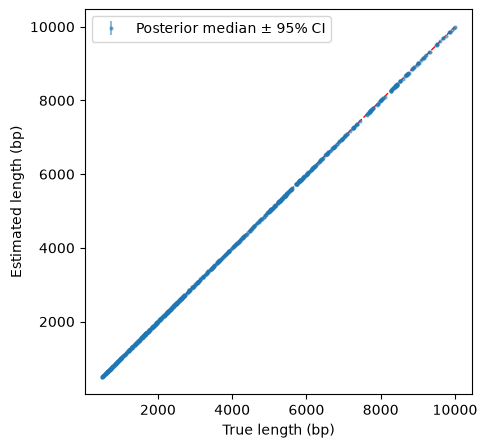

In [9]:
L_obs = x_obs[:, -1]
L_q = np.quantile(theta_post[:, :, 2], [0.025, 0.5, 0.975], axis=1)

plt.figure(figsize=(5, 5))
plt.errorbar(L_obs, L_q[1], yerr=[L_q[1] - L_q[0], L_q[2] - L_q[1]], fmt="o", ms=2, alpha=0.5,
             label="Posterior median ± 95% CI")
plt.plot([L_obs.min(), L_obs.max()], [L_obs.min(), L_obs.max()], "r--", lw=1)
plt.xlabel("True length (bp)")
plt.ylabel("Estimated length (bp)")
plt.legend()
plt.show()

## Detect hotspots

ppDoG settings of the paper for *E. coli* (Table S1): narrow bandwidth 100 kb, broad bandwidth 1 Mb,
$\tau = 0.2$, probability threshold 0.9, and minimum fold enrichment 4 (recombination)
and 100 (mutation). Blocks are placed at their start positions on the 4,938,906 bp chromosome.

In [10]:
gene_starts = gene_info["Start_pos_raw"].to_numpy()
gene_ends = gene_info["End_pos_raw"].to_numpy()
chromosome_length_bp = 4_938_906

settings = dict(
    gene_ends=gene_ends,
    narrow_bandwidth_bp=100_000,
    broad_bandwidth_bp=1_000_000,
    probability_threshold=0.90,
    residual_log_sd=0.20,
    random_state=10,
    max_gap_bp=800_000,
)

### Recombination hotspots

Detected hotspot segments:
  1.84-2.07 Mb; 22 genes; peak P=1.000; peak enrichment=7.57x
  2.79-2.91 Mb; 20 genes; peak P=1.000; peak enrichment=4.61x


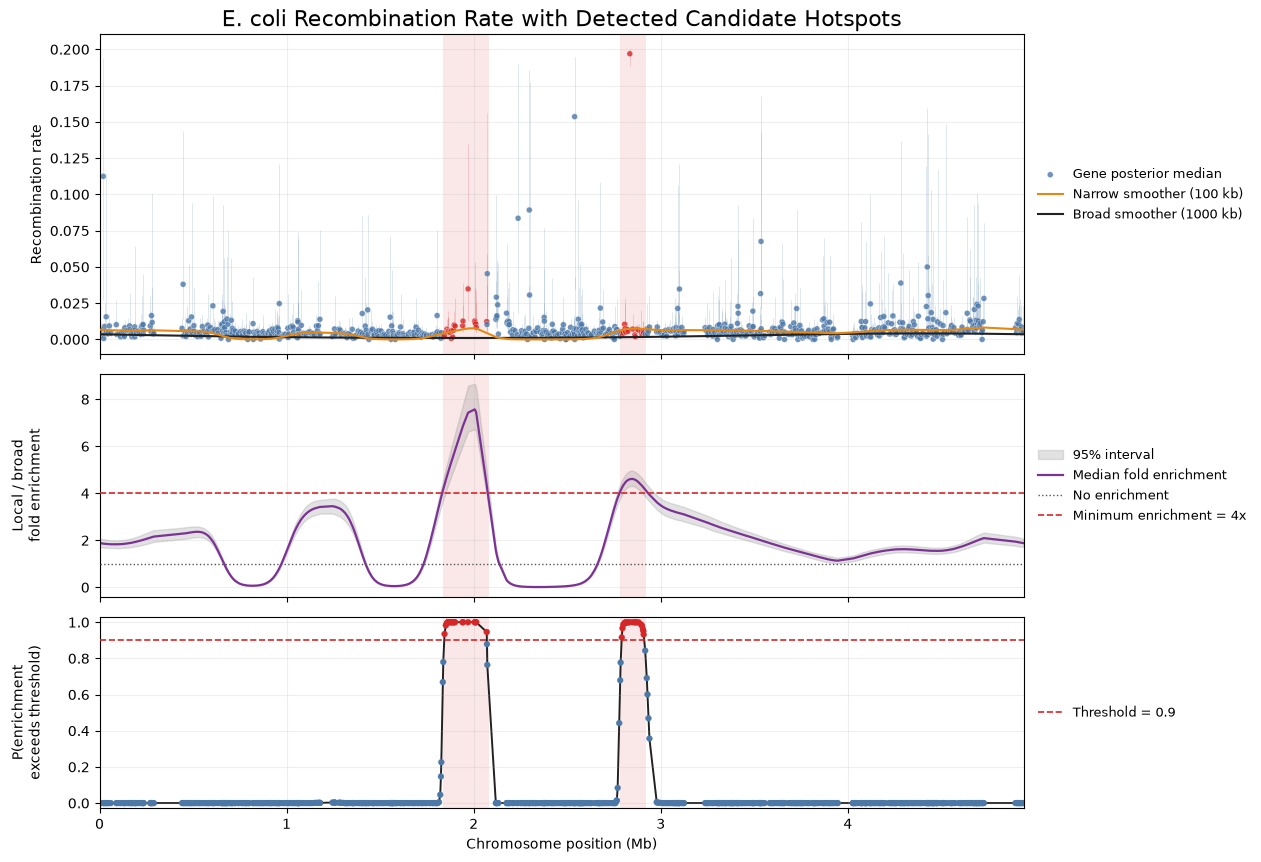

In [11]:
recomb = detect_hotspots(gene_starts, theta_post[:, :, 0], chromosome_length_bp,
                         min_fold_enrichment=4, **settings)
print(recomb.summary())

recomb.plot(
    rate_label="Recombination rate",
    title_text="E. coli Recombination Rate with Detected Candidate Hotspots"
)
plt.show()

In [12]:
recomb_hotspots = recomb.to_dataframe()
recomb_hotspots

,start_position_bp,end_position_bp,n_genes,peak_probability,peak_fold_enrichment,median_probability,wraps_origin
0,1844174.0,2071008.0,22,1.0,7.571508,1.000,False
1,2791496.0,2916774.0,20,1.0,4.613029,0.997,False


Blocks in the first recombination hotspot:

In [13]:
segments = recomb.segment_gene_indices()
gene_info.iloc[segments[0]] if segments else "No hotspot detected"

,Gene_Length,Start_pos,End_pos,Alignment,Gene_Length_raw,Start_pos_raw,End_pos_raw
Gene_ID,,,,,,,
441_1,6768,1844152,1850919,True,6769,1844174,1850942
439,5030,1851069,1856098,True,5032,1851069,1856100
437,4300,1856168,1860467,True,4302,1856168,1860469
438,2729,1860470,1863198,True,2730,1860470,1863199
433,649,1863211,1863859,True,649,1863211,1863859
434,2285,1863860,1866144,True,2285,1863860,1866144
430,7250,1866274,1873523,True,7254,1866274,1873527
429,6886,1873579,1880464,True,6912,1873579,1880490
435,655,1880491,1881145,True,656,1880491,1881146


### Mutation hotspots

Detected hotspot segments:
  1.84-2.07 Mb; 24 genes; peak P=1.000; peak enrichment=342.92x
  4.68-4.73 Mb; 19 genes; peak P=1.000; peak enrichment=342.88x


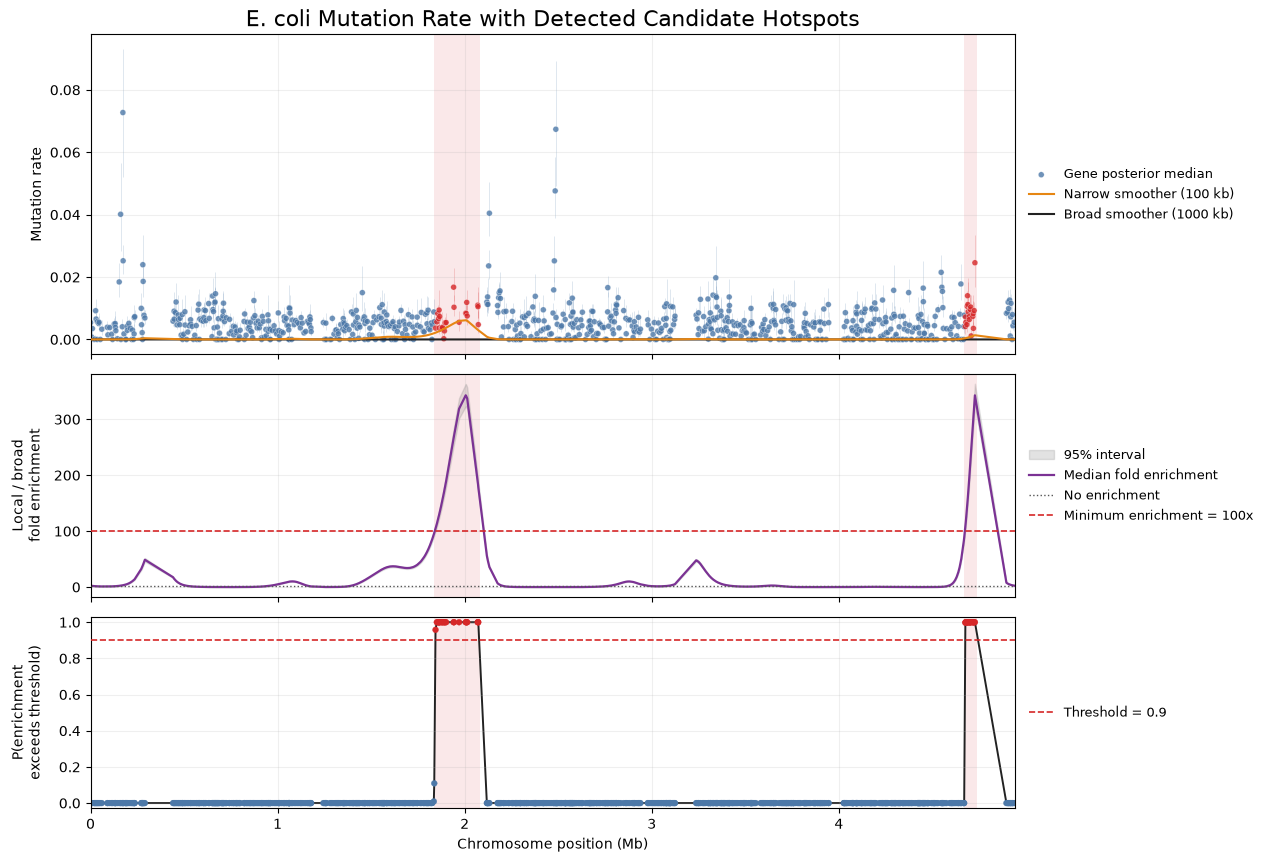

In [14]:
mutate = detect_hotspots(gene_starts, theta_post[:, :, 1], chromosome_length_bp,
                         min_fold_enrichment=100.0, **settings)
print(mutate.summary())

mutate.plot(
    rate_label="Mutation rate",
    title_text="E. coli Mutation Rate with Detected Candidate Hotspots"
)
plt.show()

In [15]:
mutate_hotspots = mutate.to_dataframe()
mutate_hotspots

,start_position_bp,end_position_bp,n_genes,peak_probability,peak_fold_enrichment,median_probability,wraps_origin
0,1844174.0,2073314.0,24,1.0,342.922483,1.0,False
1,4676291.0,4728841.0,19,1.0,342.879844,1.0,False


### Save the hotspot tables

One sheet per rate, as Table S6 of the paper.

In [16]:
save_hotspot_tables({"Recombination": recomb_hotspots, "Mutation": mutate_hotspots},
                    OUTPUT / "ecoli_hotspots.xlsx", overwrite=True)

WindowsPath('output/ecoli_hotspots.xlsx')